In [2]:
from ecephys_setup import get_session, get_units, get_spikes, clean_grating_spike_data

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

/Users/lyn/miniforge3/envs/allensdk/lib/python3.9/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
DEFAULT_SESSION_ID = 715093703
session = get_session(DEFAULT_SESSION_ID) 
session.metadata

/Users/lyn/miniforge3/envs/allensdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)
/Users/lyn/miniforge3/envs/allensdk/lib/python3.9/site-packages/hdmf/spec/namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)
/Users/lyn/miniforge3/envs/all

{'specimen_name': 'Sst-IRES-Cre;Ai32-386129',
 'session_type': 'brain_observatory_1.1',
 'full_genotype': 'Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt',
 'sex': 'M',
 'age_in_days': 118.0,
 'rig_equipment_name': 'NP.1',
 'num_units': 884,
 'num_channels': 2219,
 'num_probes': 6,
 'num_stimulus_presentations': 70388,
 'session_start_time': datetime.datetime(2019, 1, 19, 0, 54, 18, tzinfo=tzoffset(None, -28800)),
 'ecephys_session_id': 715093703,
 'structure_acronyms': ['PO',
  'PoT',
  'LP',
  'DG',
  'CA1',
  'VISp',
  nan,
  'LGd',
  'CA3',
  'VISl',
  'VISrl',
  'grey',
  'VISpm',
  'VISam',
  'APN',
  'MB'],
 'stimulus_names': ['spontaneous',
  'gabors',
  'flashes',
  'drifting_gratings',
  'natural_movie_three',
  'natural_movie_one',
  'static_gratings',
  'natural_scenes']}

In [4]:
v1_stims, v1_units = get_units(session, region="VISp")
lat_stims, lat_units = get_units(session, region="VISl")

v1_spikes = get_spikes(session, v1_stims, v1_units)
lat_spikes = get_spikes(session, lat_stims, lat_units)

v1_bins = clean_grating_spike_data(v1_spikes, v1_stims)
lat_bins = clean_grating_spike_data(lat_spikes, lat_stims)

In [5]:
v1_bins.head()

,spike_time,stimulus_presentation_id,unit_id,time_since_stimulus_presentation_onset,orientation,time_bin
0,1574.778290,3798,950930358,0.003468,315.0,"[0.0, 0.2)"
1,1574.780290,3798,950930407,0.005468,315.0,"[0.0, 0.2)"
2,1574.781290,3798,950931581,0.006468,315.0,"[0.0, 0.2)"
3,1574.782690,3798,950931254,0.007868,315.0,"[0.0, 0.2)"
4,1574.783424,3798,950931315,0.008601,315.0,"[0.0, 0.2)"


## Step 1: Make intra-regional correlation matrices between units across orientation angles

Use average firing rate of each unit, and of course remember to sort them so the comparison is fair!

In [6]:
from sklearn.metrics.pairwise import cosine_similarity

def build_orientation_matrix(spike_df):
    spike_df["orientation"] = spike_df["orientation"].astype(int)
    return (
        spike_df
        .groupby(["unit_id", "orientation"])["spike_time"]
        .size()
        .div(2) # rate = spikes / sec, and the time window is 2 seconds
        .unstack("orientation") # rows = units, columns = orientation
        .fillna(0)
    )

def plot_corr_matrix(corr_matrix, title, figsize=(8, 6), annot=True, linewidth=0.5):
    plt.figure(figsize=(7, 6))
    sns.heatmap(
        corr_matrix,
        annot=annot,          # print the value in each cell
        fmt=".2f",            # 2 decimal places
        cmap="coolwarm",      # diverging colormap
        vmin=-1, vmax=1,      # fix scale to [-1, 1]
        square=True,          # square cells
        linewidths=linewidth, # thin gridlines
        cbar_kws={"label": "Cosine similarity"},
    )
    plt.title(title)
    plt.xlabel("Orientation (°)")
    plt.ylabel("Orientation (°)")
    plt.tight_layout()
    plt.show()

def plot_orientation_similarity(spike_df, title, figsize=(8, 6)):
    # Calculate spike rate by unit and orientation
    rates_by_orientation = build_orientation_matrix(spike_df)
    
    # Center the rates to focus on variation
    mean_rates = rates_by_orientation.mean(axis=1)
    centered_rates = rates_by_orientation.sub(mean_rates, axis=0) # subtract unit's mean across orientations
    
    orient_vectors = centered_rates.T.values      # (n_orient, n_units)
    cos_sim = cosine_similarity(orient_vectors)   # (n_orient, n_orient)
    
    corr_matrix = pd.DataFrame(
        cos_sim,
        index=rates_by_orientation.columns,
        columns=rates_by_orientation.columns,
    )

    plot_corr_matrix(corr_matrix, title, figsize=figsize)

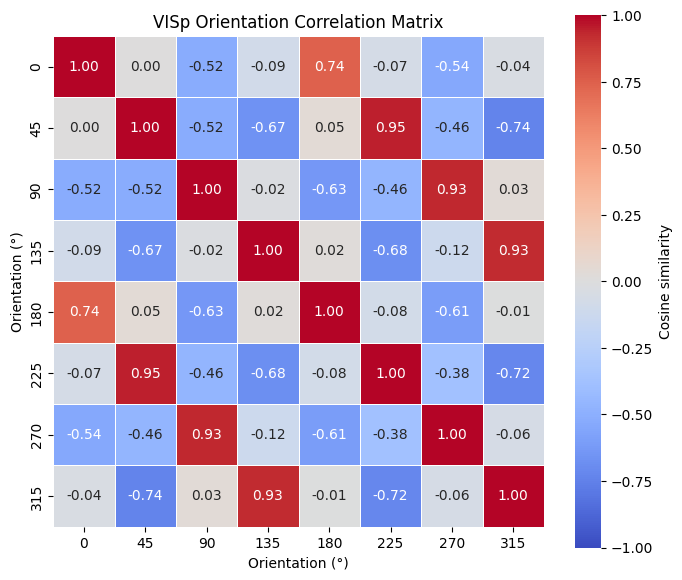

In [7]:
plot_orientation_similarity(v1_bins, "VISp Orientation Correlation Matrix")

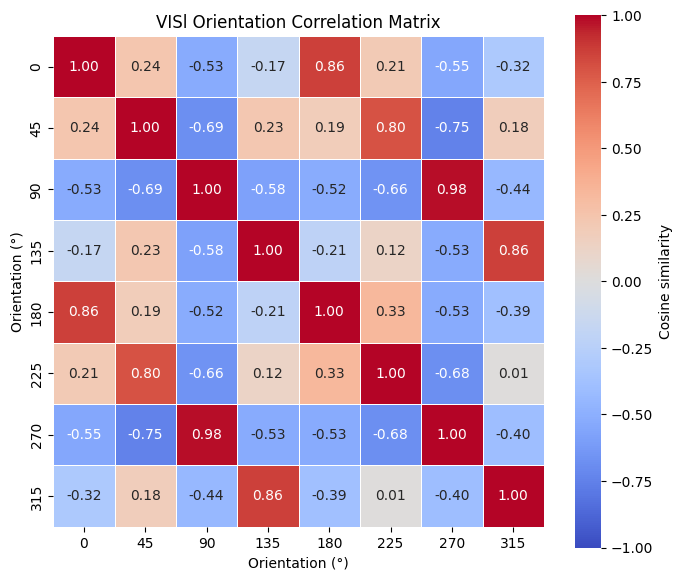

In [8]:
plot_orientation_similarity(lat_bins, "VISl Orientation Correlation Matrix")

## Step 2: Quantify representational similarity between regions using CKA 

Devise a nonparametric test (i.e. bootstrapping) to determine whether the similarity is greater or less than chance.

In [9]:
def build_trial_matrix(df):
    # rows = stimulus_presentation_id, cols = unit_id, values = spike rate
    return (
        df
        .groupby(["stimulus_presentation_id", "unit_id"])
        .size()
        .rename("spikes")
        .unstack("unit_id")
        .div(2) # rate = spikes / sec, and the time window is 2 seconds
        .fillna(0)
        .sort_index()
    )

build_trial_matrix(v1_bins).head()

unit_id,950930105,950930145,950930215,950930237,950930276,950930340,950930358,950930375,950930392,950930407,...,950932578,950932696,950933698,950933732,950933840,950933890,950933907,950933924,950933960,950934181
stimulus_presentation_id,,,,,,,,,,,,,,,,,,,,,
3798,1.0,0.5,16.0,9.0,4.0,5.0,17.0,0.5,5.5,56.0,...,19.0,1.0,4.0,2.5,5.0,0.0,3.5,0.0,2.5,2.0
3799,0.5,0.0,38.0,6.5,6.5,6.0,4.0,1.0,11.0,45.5,...,3.0,0.0,1.5,0.5,2.5,0.0,0.0,0.0,0.0,0.0
3800,0.0,0.5,16.0,86.0,17.5,20.5,2.5,1.0,2.5,70.0,...,10.5,0.5,1.5,0.5,6.0,0.0,4.5,0.0,6.0,1.0
3801,1.0,0.5,27.0,7.5,4.5,4.0,3.5,0.0,9.5,85.0,...,7.0,0.0,0.5,0.5,9.5,0.5,0.5,0.0,3.0,0.0
3802,1.0,0.0,17.5,2.0,6.0,0.0,10.5,1.0,11.0,52.0,...,2.5,0.5,0.5,5.0,4.0,0.5,0.5,0.5,0.0,0.5


In [10]:
def center_gram(K):
    # Double-centers the matrix across columns and rows
    n = K.shape[0]
    H = np.eye(n) - np.ones((n, n)) / n
    return H @ K @ H

def align_regions(region_A_spikes, region_B_spikes):
    X = build_trial_matrix(region_A_spikes) 
    Y = build_trial_matrix(region_B_spikes) 
    
    # Align trials so they're the same same presentations in the same order in both regions
    common = X.index.intersection(Y.index)
    X = X.loc[common].values
    Y = Y.loc[common].values

    return X, Y

def cka_linear(X, Y):
    Kc = center_gram(X @ X.T)
    Lc = center_gram(Y @ Y.T)
    return np.sum(Kc * Lc) / np.sqrt(np.sum(Kc * Kc) * np.sum(Lc * Lc))

def run_cka(region_A_spikes, region_B_spikes):
    X, Y = align_regions(region_A_spikes, region_B_spikes)
    return cka_linear(X, Y)

obs_CKA = run_cka(v1_bins, lat_bins)
print(f"observed CKA: {obs_CKA}")

observed CKA: 0.511693561900744


**Null hypothesis:** region A's representational geometry doesn't match region B's representational geometry. \
Therefore, shuffling the row labels (presentation IDs) of region A will not affect the CKA score.

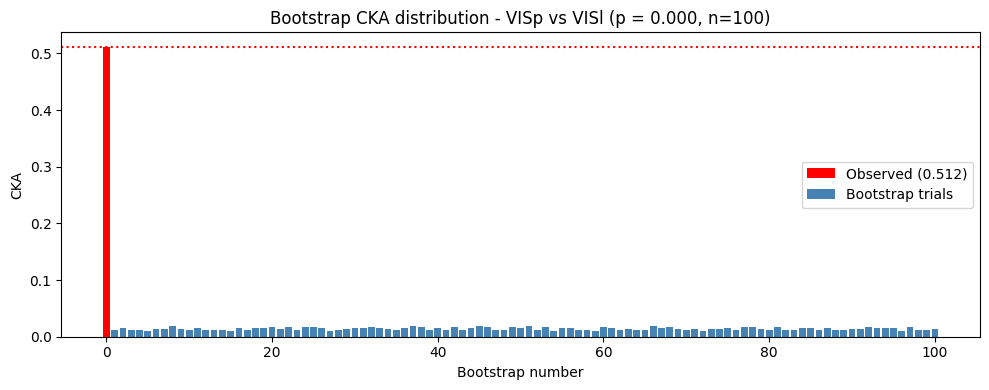

0.0

In [24]:
def bootstrap_cka_trial(X, Y):
    # shuffle the row labels of X, then run CKA
    X_row_indices = np.arange(X.shape[0])
    np.random.shuffle(X_row_indices)
    shuffled_X = X[X_row_indices]
    perm_CKA = cka_linear(shuffled_X, Y)
    return perm_CKA

def plot_bootstraps(bootstrap_CKAs, obs_CKA, p, n_trials, title):
    fig, ax = plt.subplots(figsize=(10, 4))

    # observed CKA: red bar on the left
    ax.bar(0, obs_CKA, color="red", width=0.8, label=f"Observed ({obs_CKA:.3f})")

    # bootstrap distribution: blue bars to the right
    x = np.arange(1, n_trials + 1)
    ax.bar(x, bootstrap_CKAs, color="steelblue", width=0.8, label="Bootstrap trials")

    # dotted line across the top at the observed value
    ax.axhline(obs_CKA, color="red", linestyle=":", linewidth=1.5)

    ax.set_xlabel("Bootstrap number")
    ax.set_ylabel("CKA")
    if title is None:
        ax.set_title(f"Bootstrap CKA distribution (p = {p:.3f}, n={n_trials})")
    else:
        ax.set_title(f"Bootstrap CKA distribution - {title} (p = {p:.3f}, n={n_trials})")
    ax.legend(loc="center right")
    plt.tight_layout()
    plt.show()

def bootstrap_region_cka(region_A_spikes, region_B_spikes, n_trials=100, plot=False, title=None):
    X, Y = align_regions(region_A_spikes, region_B_spikes)
    null_CKAs = np.array([bootstrap_cka_trial(X, Y) for _ in range(n_trials)])
    
    obs_CKA = cka_linear(X, Y)
    p = np.mean(null_CKAs >= obs_CKA)

    if plot:
        plot_bootstraps(null_CKAs, obs_CKA, p, n_trials, title)
    
    return p

bootstrap_region_cka(v1_bins, lat_bins, n_trials=100, plot=True, title="VISp vs VISl")

## Step 3: Analyze trial-by-trial correlations, and bootstrap to see if it's more than chance would have

Compare correlation (cosine similarity) matrices that compare each trial to every other trial. Look at the correlation matrices ordered by trial number and by grating orientation. Are there visible indications that nearby trials are more correlated than more distant trials? Are there visible indications that there are correlations between trials with the same orientation? Devise and implement a test to determine if the trial-by-trial similarity matrices from each regions are more or less similar to each other than chance. Compare to similarity by orientation.

In [12]:
v1_bins[["orientation", "unit_id"]].drop_duplicates().sort_values(by=["orientation", "unit_id"])

,orientation,unit_id
8389,0,950930105
7361,0,950930145
7282,0,950930215
7321,0,950930237
7218,0,950930276
...,...,...
8968,315,950933890
56,315,950933907
15864,315,950933924
85,315,950933960


In [13]:
def sort_by_orientation(spike_df, rate_df):
    sorted_trial_ids = (spike_df[["orientation", "stimulus_presentation_id"]]
        .drop_duplicates()
        .sort_values(by=["orientation", "stimulus_presentation_id"])["stimulus_presentation_id"]
    )
    return rate_df.reindex(index=sorted_trial_ids)

In [14]:
build_trial_matrix(v1_bins).iloc[:, 0]

stimulus_presentation_id
3798      1.0
3799      0.5
3800      0.0
3801      1.0
3802      1.0
         ... 
49426     6.5
49427    11.5
49428    14.0
49429    12.5
49430    15.5
Name: 950930105, Length: 547, dtype: float64

In [15]:
def make_trial_corr_matrix(spike_df, sort_orientation=False):
    # Calculate spike rates per trial and unit
    rates_by_trial = build_trial_matrix(spike_df)
    if sort_orientation:
        # Sort trials if needed
        rates_by_trial = sort_by_orientation(spike_df, rates_by_trial)

    # Mean center each unit's firing rates so we focus on variation
    mean_rates = rates_by_trial.mean()
    centered_rates = rates_by_trial.sub(mean_rates, axis=1)

    # Create cosine similarity matrix
    trial_vectors = centered_rates.values
    cos_sim = cosine_similarity(trial_vectors) # (n_trials, n_trials)
    return pd.DataFrame(cos_sim)

def plot_big_corr_matrix(corr_matrix, title, block_bounds=None, block_labels=None):
    fig, ax = plt.subplots(figsize=(9, 9))
    im = ax.imshow(corr_matrix, cmap="coolwarm", vmin=-1, vmax=1, interpolation="nearest")
    if block_bounds is not None:
        for b in block_bounds[1:-1]:
            ax.axhline(b, color="black", lw=0.6)
            ax.axvline(b, color="black", lw=0.6)
    if block_labels is not None:
        centers = [(block_bounds[i] + block_bounds[i+1])/2 for i in range(len(block_bounds)-1)]
        ax.set_xticks(centers); ax.set_xticklabels(block_labels, rotation=0)
        ax.set_yticks(centers); ax.set_yticklabels(block_labels)
    fig.colorbar(im, ax=ax, label="Cosine similarity", shrink=0.8)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(title.replace(" ", "_") + ".png", dpi=300, bbox_inches="tight")
    plt.show()

def plot_trial_similarity(spike_df, title, sort_orientation=False):
    corr_matrix = make_trial_corr_matrix(spike_df, sort_orientation=sort_orientation)

    if sort_orientation:
        # orientation of each trial, in sorted order
        orient_per_trial = (
            spike_df.drop_duplicates("stimulus_presentation_id")
            .set_index("stimulus_presentation_id")["orientation"]
            .sort_values()
            .astype(int)
            .values
        )
        # Block boundaries where orientation changes
        changes = np.where(np.diff(orient_per_trial) != 0)[0]
        bounds = [0] + changes.tolist() + [len(orient_per_trial)]
        labels = np.unique(orient_per_trial)
        plot_big_corr_matrix(corr_matrix, title, block_bounds=bounds, block_labels=labels)
    else:
        plot_big_corr_matrix(corr_matrix, title)

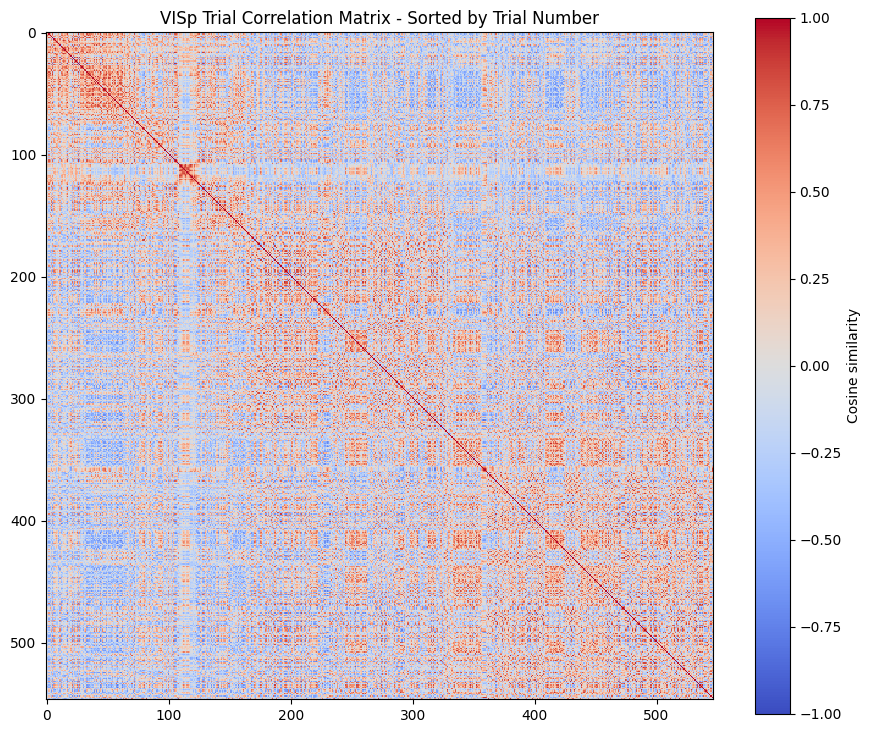

In [16]:
plot_trial_similarity(v1_bins, "VISp Trial Correlation Matrix - Sorted by Trial Number", sort_orientation=False)

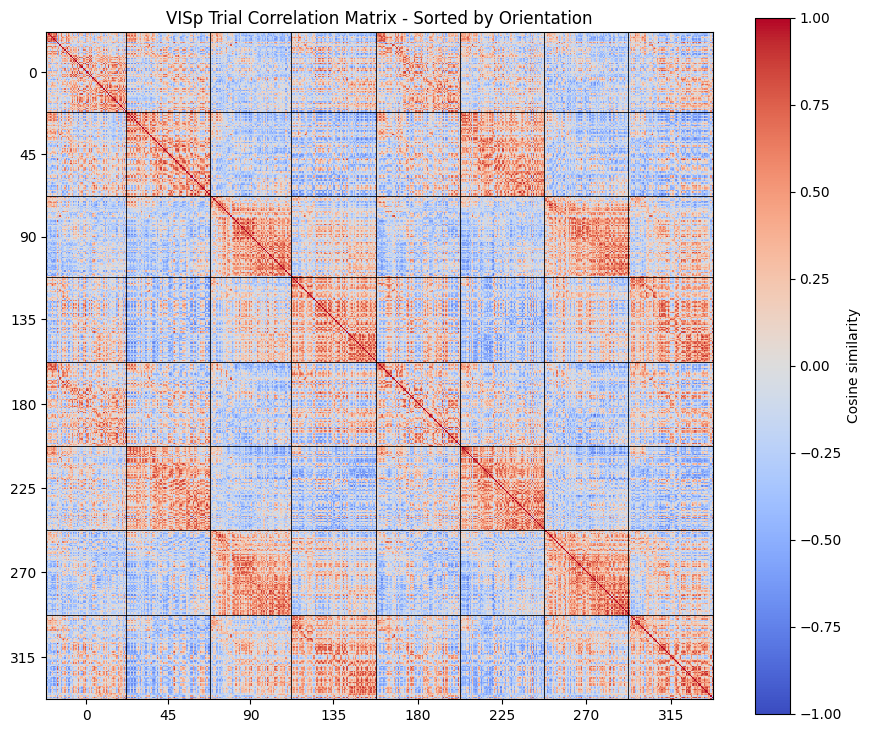

In [17]:
plot_trial_similarity(v1_bins, "VISp Trial Correlation Matrix - Sorted by Orientation", sort_orientation=True)

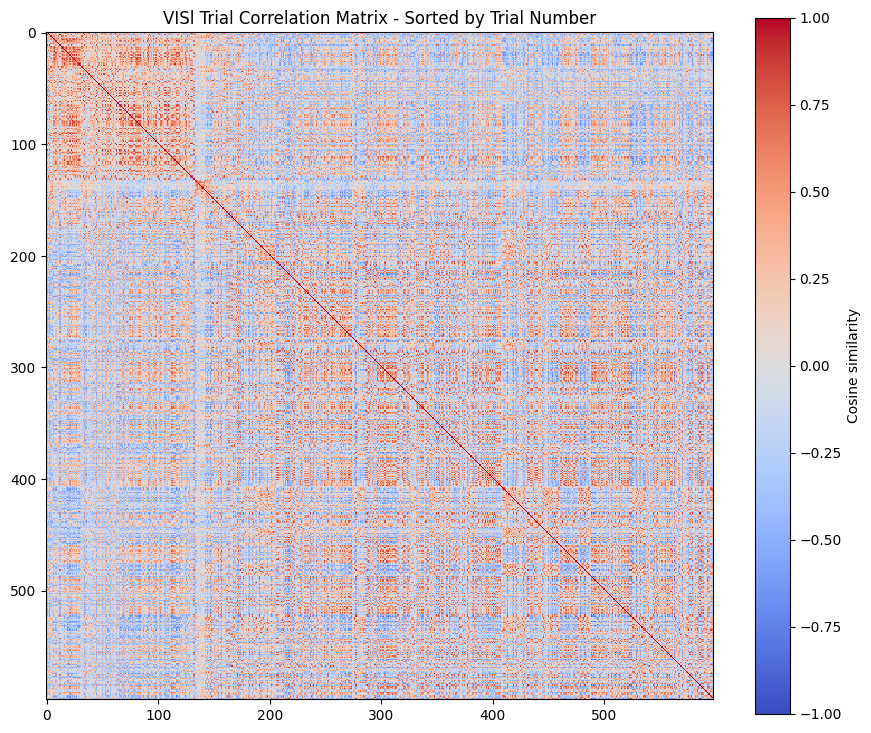

In [18]:
plot_trial_similarity(lat_bins, "VISl Trial Correlation Matrix - Sorted by Trial Number", sort_orientation=False)

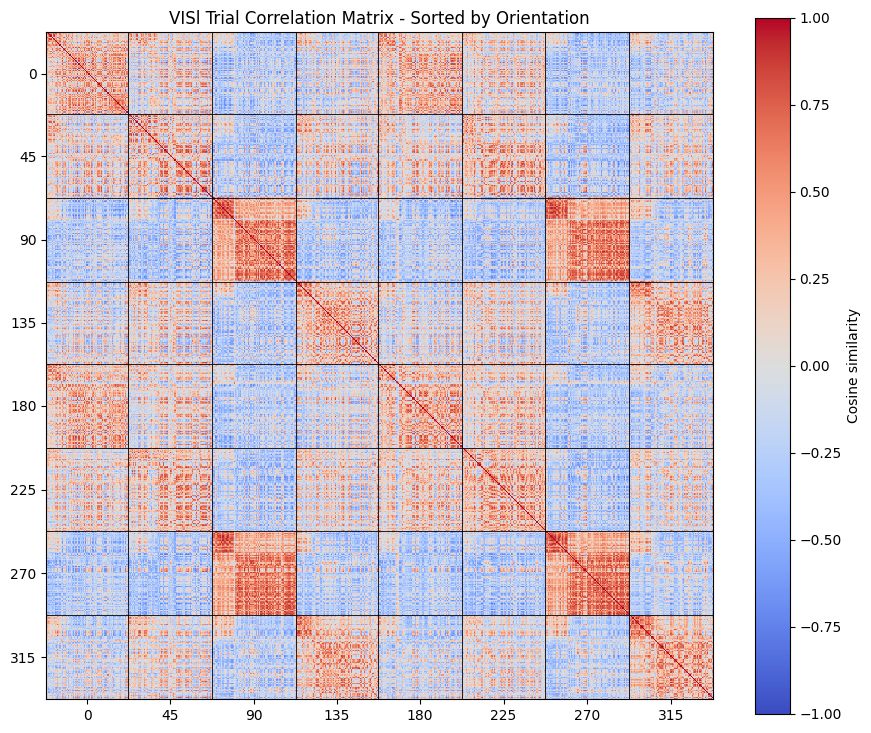

In [19]:
plot_trial_similarity(lat_bins, "VISl Trial Correlation Matrix - Sorted by Orientation", sort_orientation=True)

In [26]:
def align_trials(region_A_spikes, region_B_spikes):
    # Align trials so they're the same same presentations in the same order in both regions
    region_A_trials = region_A_spikes["stimulus_presentation_id"].unique()
    region_B_trials = region_B_spikes["stimulus_presentation_id"].unique()
    common_trials = np.intersect1d(region_A_trials, region_B_trials)
    X = region_A_spikes.query("stimulus_presentation_id in @common_trials")
    Y = region_B_spikes.query("stimulus_presentation_id in @common_trials")
    return X, Y

def bootstrap_trial_cka(region_A_spikes, region_B_spikes, n_trials=100, plot=False, title=None):
    filtered_region_A, filtered_region_B = align_trials(region_A_spikes, region_B_spikes)
    X, Y = make_trial_corr_matrix(filtered_region_A).values, make_trial_corr_matrix(filtered_region_B).values
    null_CKAs = np.array([bootstrap_cka_trial(X, Y) for _ in range(n_trials)])

    obs_CKA = cka_linear(X, Y)
    p = np.mean(null_CKAs >= obs_CKA)

    if plot:
        plot_bootstraps(null_CKAs, obs_CKA, p, n_trials, title)
    
    return p

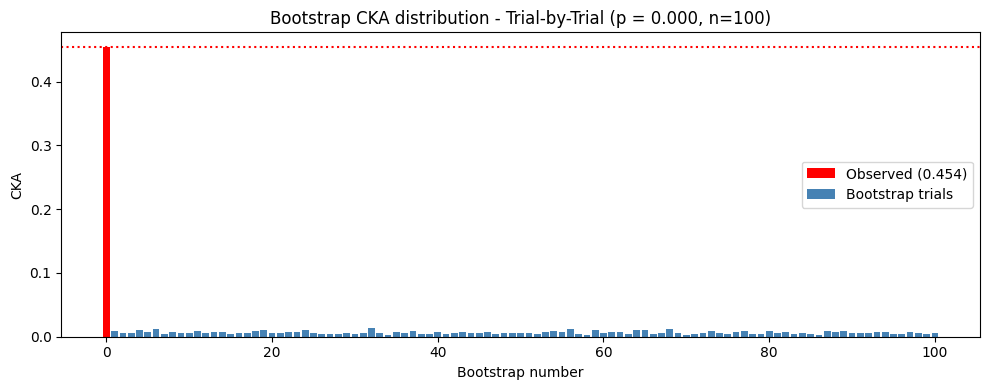

0.0

In [27]:
bootstrap_trial_cka(v1_bins, lat_bins, n_trials=100, plot=True, title="Trial-by-Trial")

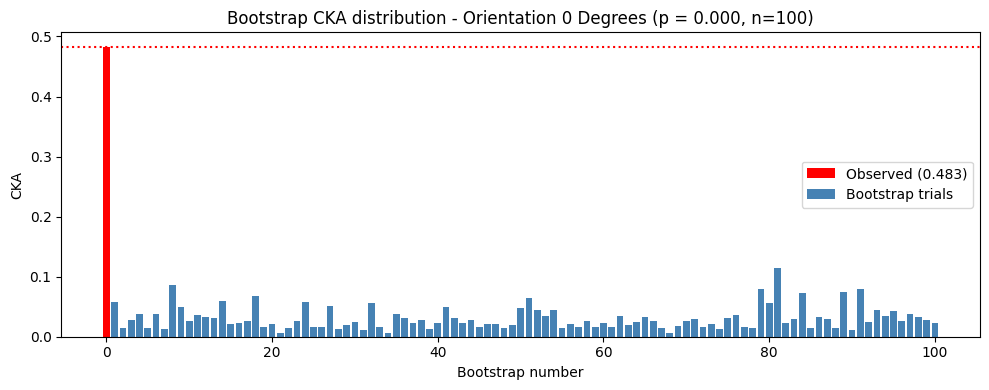

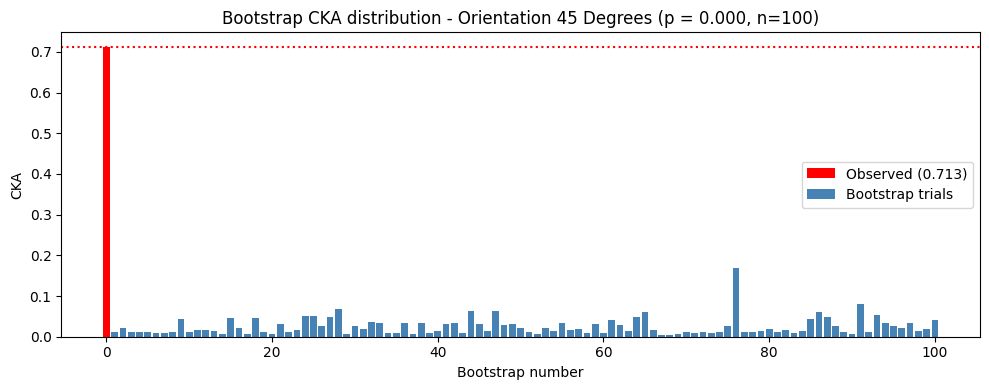

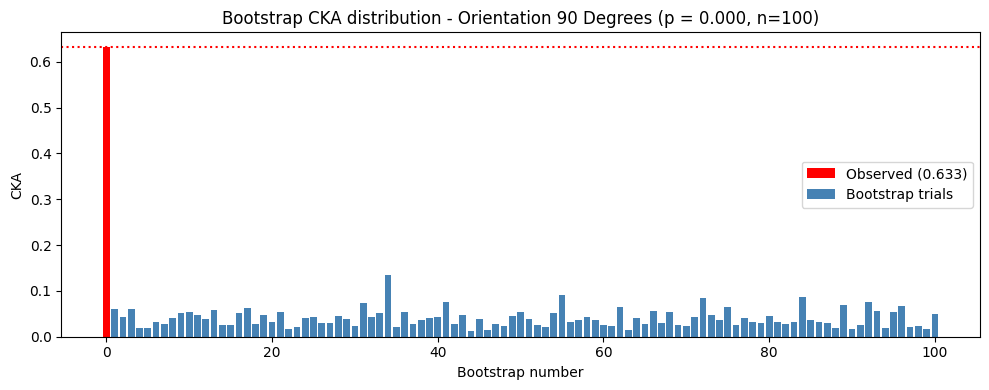

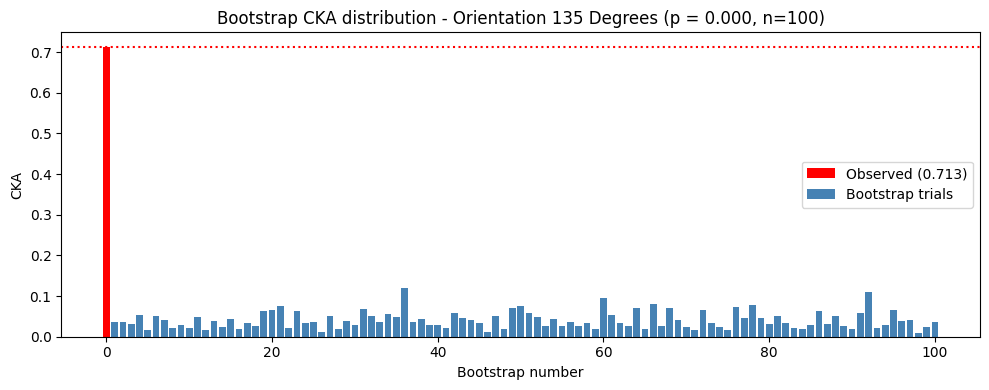

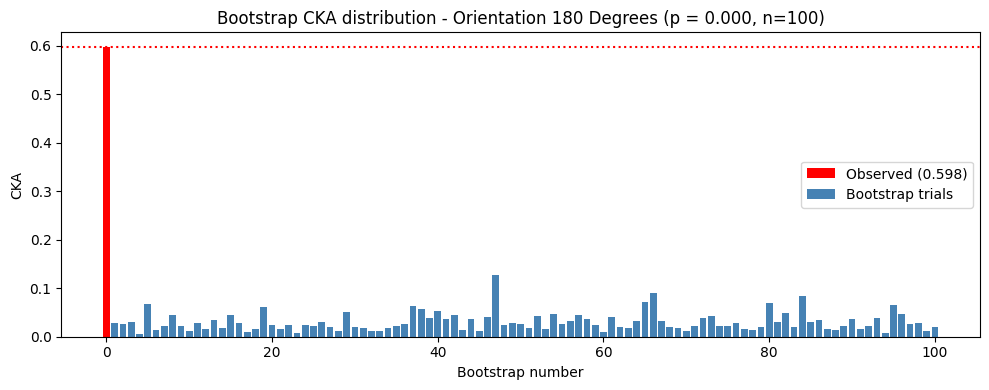

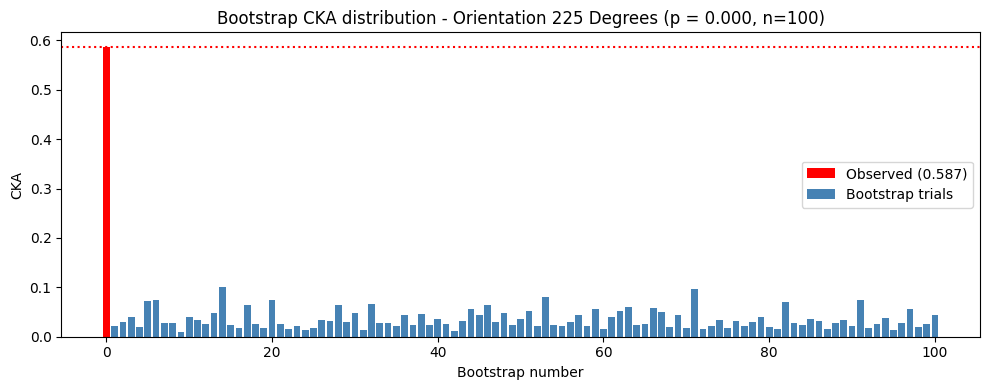

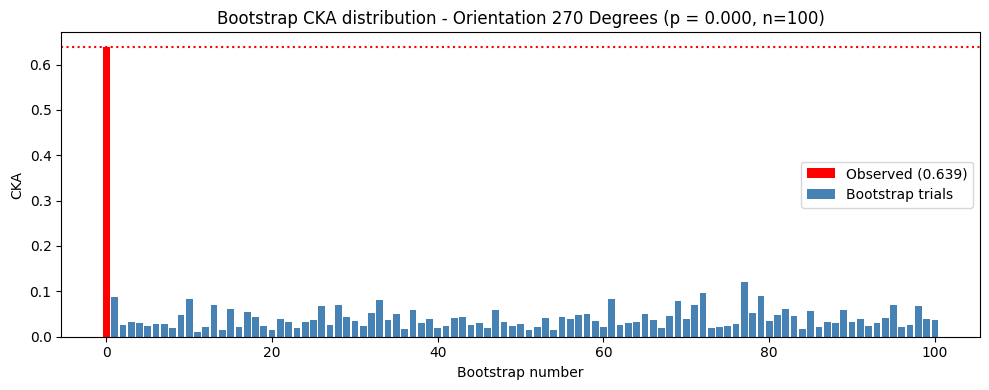

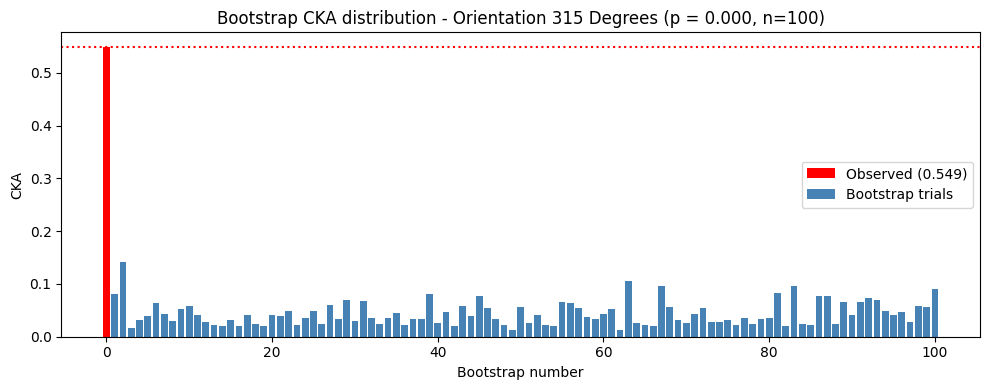

In [25]:
def cka_within_orientation(region_A_spikes, region_B_spikes, orientation, n_trials=500, plot=False, title=None):
    filtered_A = region_A_spikes[region_A_spikes["orientation"] == orientation]
    filtered_B = region_B_spikes[region_B_spikes["orientation"] == orientation]
    A, B = align_trials(filtered_A, filtered_B)
    X, Y = make_trial_corr_matrix(A).values, make_trial_corr_matrix(B).values

    obs_CKA = cka_linear(X, Y)
    null_CKAs = np.array([bootstrap_cka_trial(X, Y) for _ in range(n_trials)])

    p = np.mean(null_CKAs >= obs_CKA)
    
    if plot:
        plot_bootstraps(null_CKAs, obs_CKA, p, n_trials, title)
    
    return p

orientations = np.arange(0, 360, 45)
for angle in orientations:
    cka_within_orientation(v1_bins, lat_bins, angle, n_trials=100, plot=True, title=f"Orientation {angle} Degrees")

In [ ]:
def plot_orientation_ckas(angles, ckas, title="Cross-region CKA by orientation"):
    fig, ax = plt.subplots(figsize=(9, 5))

    ax.plot(angles, ckas, color="tab:blue", marker="o",
            markersize=8, linewidth=2)

    ax.set_xticks(angles)
    ax.set_xticklabels([f"{a:.0f}°" for a in angles])
    ax.set_xlabel("Grating orientation")
    ax.set_ylabel("CKA")
    ax.set_ylim(0, max(ckas.max() * 1.15, 0.1))
    ax.set_title(title)
    ax.grid(alpha=0.2)
    for spine in ["top", "right"]:
        ax.spines[spine].set_visible(False)

    plt.tight_layout()
    plt.show()

def orientation_ckas(region_A_spikes, region_B_spikes):
    orientations = np.arange(0, 360, 45)
    obs_CKAs = []
    for angle in orientations:
        filtered_A = region_A_spikes[region_A_spikes["orientation"] == angle]
        filtered_B = region_B_spikes[region_B_spikes["orientation"] == angle]
        X, Y = align_trials(filtered_A, filtered_B)
        obs_CKAs.append(cka_linear(X, Y))

    plot_orientation_ckas(orientations, obs_CKAs)

orientation_ckas(v1_bins, lat_bins)  